# Preparação do dataset de Emendas Parlamentares e recomendações para o treinamento

## 1. Etapas realizadas na preparação dos dados

| Etapa                             | Procedimento realizado                                                                                                                                                                              |
| --------------------------------- | --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Filtragem temporal                | Remoção dos registros referentes a 2025 e 2026, pois emendas mais recentes podem não ter tido tempo suficiente para percorrer as etapas de aprovação, execução orçamentária e repasse dos recursos. |
| Remoção de colunas                | Exclusão de variáveis irrelevantes, redundantes ou inadequadas à análise, incluindo valores financeiros de etapas intermediárias da execução orçamentária, para evitar vazamento de informação.     |
| Correção dos tipos de dados       | Códigos identificadores tratados como texto; variáveis quantitativas convertidas para tipos numéricos; marcadores textuais de ausência, como hífens e campos vazios, tratados adequadamente.        |
| Tratamento de valores ausentes    | Valores ausentes mantidos sem preenchimento nesta etapa. A imputação será realizada posteriormente, durante o treinamento.                                                                          |
| Preservação dos valores originais | Não foram aplicadas normalização, padronização ou codificação de variáveis categóricas. Essas transformações serão definidas na etapa de treinamento.                                               |
| Exportação                        | Preparação do conjunto de dados para exportação em CSV, mantendo a variável original `Valor Pago` para a construção da variável-alvo.                                                               |

Quantidade de registros após a filtragem temporal: 36.229.

## 2. Verificações pendentes antes do treinamento

- Código Município IBGE: verificar se a coluna `Código Município IBGE` ainda está presente no CSV final. Caso esteja, removê-la antes do treinamento, pois foi definida apenas para integração das tabelas, não sendo utilizada como variável preditora.
- Integridade dos valores ausentes: conferir a quantidade de valores ausentes por coluna no arquivo final. A presença de ausências nas variáveis preditoras não significa que o dataset esteja incorreto.

## 3. Recomendações de normalização e pré-processamento

O pré-processamento deverá ser realizado pelo responsável pelo treinamento, preferencialmente por meio de um pipeline. As transformações devem ser ajustadas exclusivamente com os dados de treino e, posteriormente, aplicadas à validação e ao teste.

### 3.1. Variáveis numéricas

| Tipo de variável                         | Exemplos                                                                                                                                                                                                                                                                             | Recomendação                                                                                                                                           |
| ---------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ | ------------------------------------------------------------------------------------------------------------------------------------------------------ |
| Indicadores socioeconômicos              | `densidade_demografica`, `pib_per_capita`, `rendimento_medio_sal_min`, `taxa_escolarizacao_6_14`, `arborizacao_vias_publicas`                                                                                                                                                        | Utilizar `StandardScaler` como abordagem inicial.                                                                                                      |
| Variáveis de contagem                    | `docentes_ensino_fundamental`, `docentes_ensino_medio`, `estabelecimentos_ensino_fundamental`, `estabelecimentos_ensino_medio`, `estabelecimentos_saude_sus`, `matriculas_ensino_fundamental`, `matriculas_ensino_medio`, `pessoal_ocupado`, `populacao_censo`, `populacao_estimada` | Verificar a distribuição de cada variável, pois podem apresentar assimetria.                                                                           |
| Variáveis financeiras                    | `despesas_brutas_empenhadas`, `receitas_brutas_realizadas`                                                                                                                                                                                                                           | Avaliar a aplicação de `log1p` antes da padronização, caso apresentem assimetria acentuada e valores não negativos.                                    |
| Variáveis de área e população            | `area_km2`, `area_urbanizada_km2`, `populacao_censo`, `populacao_estimada`, `pessoal_ocupado`                                                                                                                                                                                        | Analisar histogramas e estatísticas descritivas; considerar transformações logarítmicas quando justificadas.                                           |
| Indicadores percentuais ou proporcionais | `arborizacao_vias_publicas`, `esgotamento_sanitario_adequado`, `populacao_ocupada`, `populacao_renda_per_capita_maior_meio_salario`, `taxa_escolarizacao_6_14`, `urbanizacao_vias_publicas`                                                                                          | Considerar `StandardScaler`, verificando previamente se os valores estão expressos em porcentagem, proporção ou outra unidade.                         |
| Variáveis com muitos zeros               | `internacoes_diarreia_sus_100mil`                                                                                                                                                                                                                                                    | Não confundir zeros com dados ausentes. A padronização pode ser suficiente como ponto de partida.                                                      |
| `transferencias_correntes`               | Percentual das transferências correntes em relação às receitas correntes brutas realizadas pelo município                                                                                                                                                                            | Aplicar `StandardScaler` ou dividir os valores por 100, caso estejam expressos em porcentagem. Não utilizar transformação logarítmica automaticamente. |

Outras recomendações:

- Outliers: identificar valores extremos antes de aplicar as transformações.
- Valores legítimos: não remover automaticamente observações com magnitudes muito elevadas.
- Alternativa ao StandardScaler: comparar com `RobustScaler`, que utiliza mediana e intervalo interquartil e tende a ser menos sensível a valores extremos.
- Configuração inicial: testar `StandardScaler` para as variáveis numéricas e avaliar `log1p` apenas para as variáveis não negativas cuja distribuição justifique seu uso.

A escolha das transformações deverá ser validada experimentalmente, sem pressupor que uma única técnica será a melhor para todas as variáveis.

### 3.2. Variáveis categóricas

| Situação                                      | Recomendação                                                                                                                                                                                    |
| --------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Categorias comuns                             | Aplicar `One-Hot Encoding` em variáveis como `Tipo de Emenda`, `Região`, `bioma` e `sistema_costeiro_marinho`, além dos códigos orçamentários mantidos como preditores.                         |
| Códigos de função, subfunção, programa e ação | Tratar como categorias, mesmo quando representados por números. Não aplicar `StandardScaler` nem interpretar diferenças entre códigos como distâncias significativas.                           |
| Alta cardinalidade                            | Verificar a quantidade de categorias distintas antes da codificação, pois a expansão pode gerar muitos atributos. Avaliar a utilidade da variável e estratégias alternativas quando necessário. |
| Categorias desconhecidas                      | Configurar o codificador para aceitar categorias que não apareceram no treino. No scikit-learn, pode-se utilizar `handle_unknown='ignore'`.                                                     |

### 3.3. Tratamento dos valores ausentes

| Tipo de dado ou situação | Tratamento recomendado ou realizado                                                                                                                        |
| ------------------------ | ---------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Variáveis numéricas      | Utilizar a mediana como opção inicial de imputação, especialmente em distribuições assimétricas.                                                           |
| Variáveis categóricas    | Utilizar a categoria mais frequente ou uma categoria explícita para indicar ausência, conforme a natureza do problema.                                     |
| `mortalidade_infantil`   | Variável removida do dataset devido a inconsistências identificadas nos dados.                                                                             |
| Variáveis com zeros      | Não substituir automaticamente zeros por valores ausentes. Em indicadores como `internacoes_diarreia_sus_100mil`, o zero pode representar um valor válido. |

Regra fundamental: a imputação deverá ser ajustada apenas no conjunto de treino. Os mesmos valores de referência deverão ser aplicados à validação e ao teste, sem recalcular medianas ou frequências nesses conjuntos.

## 4. Recomendações para o treinamento do modelo

### 4.1. Definição da variável-alvo

Caso seja mantida a proposta de classificação binária, a variável `Valor Pago` deverá ser utilizada para construir o alvo.

| Condição de `Valor Pago` | Classe | Interpretação |
| ------------------------ | ------ | ------------- |
| Igual a zero             | 0      | Sem pagamento |
| Superior a zero          | 1      | Com pagamento |

Procedimentos:

- Criar a variável-alvo a partir de `Valor Pago`.
- Remover a coluna original das variáveis preditoras após a criação do alvo, evitando vazamento de informação.

### 4.2. Divisão dos dados e prevenção de vazamento

- Divisão dos conjuntos: separar os registros em treino, validação e teste.
- Estratificação: considerar uma divisão estratificada para preservar aproximadamente a proporção das classes em cada conjunto.
- Pipeline de pré-processamento: ajustar imputação, codificação, normalização e seleção de variáveis exclusivamente com os dados de treino.
- Generalização por município: caso o objetivo seja avaliar o desempenho em municípios ainda não vistos, considerar uma estratégia de separação por município, pois diferentes emendas podem compartilhar indicadores municipais.

### 4.3. Modelos e hiperparâmetros

| Ação                 | Recomendação                                                                                                                          |
| -------------------- | ------------------------------------------------------------------------------------------------------------------------------------- |
| Modelo de referência | Comparar os resultados da rede neural com um modelo simples de referência, se compatível com o escopo do trabalho.                    |
| Arquiteturas         | Testar pelo menos três configurações de MLP (Multilayer Perceptron).                                                                  |
| Hiperparâmetros      | Variar número de camadas, quantidade de neurônios, taxa de aprendizado e outros parâmetros relevantes.                                |
| Otimização           | Se for utilizado Optuna, realizar a busca de hiperparâmetros com base na validação, sem utilizar o conjunto de teste durante a busca. |

### 4.4. Métricas de avaliação

A distribuição observada no dataset é a seguinte:

Sem pagamento — classe 0

## 67,32%

Com pagamento — classe 1

## 32,68%

Devido ao desequilíbrio entre as classes, é importante verificar se o modelo não está favorecendo a classe majoritária.

| Métrica            | Finalidade                                                         |
| ------------------ | ------------------------------------------------------------------ |
| Acurácia           | Mede a proporção total de classificações corretas.                 |
| Precisão           | Mede a proporção de previsões positivas que são positivas de fato. |
| Revocação (Recall) | Mede a proporção de positivos reais identificados pelo modelo.     |
| F1-score           | Representa o equilíbrio entre precisão e revocação.                |
| Matriz de confusão | Apresenta a distribuição de acertos e erros por classe.            |

### 4.5. Avaliação final e documentação

1. Selecionar o modelo: escolher a arquitetura e os hiperparâmetros com base nos resultados de treino e validação.
2. Realizar a avaliação final: utilizar o conjunto de teste somente após a seleção do modelo.
3. Documentar os resultados, registrando:
   - Transformações aplicadas;
   - Arquiteturas avaliadas;
   - Hiperparâmetros utilizados;
   - Métricas obtidas;
   - Custos computacionais;
   - Limitações dos dados e do modelo.

In [ ]:
# @title
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# @title
file_id = "14TNiJeD86YOmHNh5mkpwTkYMp5qKfV5T"
output_file = "EmendasParlamentaresCidadesIBGE.csv"

In [ ]:
# @title
import gdown

gdown.download(
    id=file_id,
    output=output_file,
    quiet=False
)

Downloading...
From: https://drive.google.com/uc?id=14TNiJeD86YOmHNh5mkpwTkYMp5qKfV5T
To: /content/EmendasParlamentaresCidadesIBGE.csv
100%|██████████| 39.6M/39.6M [00:00<00:00, 64.3MB/s]


'EmendasParlamentaresCidadesIBGE.csv'

##Dicionário dos dados
**Por Emenda Parlamentar**

| Código da Emenda | Identificador da emenda parlamentar, composto por 12 dígitos: 4 do ano da emenda + 4 do código do autor + 4 do número da emenda do autor. |
| --- | --- |
| Ano da Emenda | Ano em que emenda foi proposta. |
| Tipo da Emenda | Descreve o tipo de emenda parlamentar. |
| Código do Autor da Emenda | Código do autor da emenda parlamentar, conforme registrado no Sistema de Administração Financeira do Governo Federal - SIAFI. |
| Nome do Autor da Emenda | Nome do autor da emenda parlamentar, conforme registrado no Sistema de Administração Financeira do Governo Federal - SIAFI. |
| Número da Emenda | Número da emenda parlamentar, conforme registrado no Sistema de Administração Financeira do Governo Federal - SIAFI. |
| Localidade do Gasto | Atributo do Plano de Trabalho que indica, durante a execução da despesa, a região onde a despesa ocorre. |
| Código Município IBGE | Código IBGE do município de destinação do recurso. Este campo poderá estar em branco, a depender da localidade de aplicação. |
| Município | Nome do município de destinação do recurso. Este campo poderá estar em branco, a depender da localidade de aplicação. |
| Código UF IBGE | Código IBGE do estado de destinação do recurso. Este campo poderá estar em branco, a depender da localidade de aplicação. |
| UF | Nome do estado de destinação do recurso. Este campo poderá estar sem informação, a depender da localidade de aplicação. |
| Região | Região de destinação do recurso. |
| Código Função | Código da Função em que foi classificada a despesa associada à emenda parlamentar.<br>Função - Representa o maior nível de agregação das diversas áreas de atuação do setor público. Reflete a competência institucional do órgão, como, por exemplo, cultura, educação, saúde, defesa, que guarda relação com os respectivos Ministérios.<br>Fonte: Manual Técnico do Orçamento. |
| Nome Função | Nome da Função em que foi classificada a despesa associada à emenda parlamentar. |
| Código Subfunção | Código da Subfunção em que foi classificada a despesa associada à emenda parlamentar.<br>Subfunção - representa um nível de agregação imediatamente inferior à função e deve evidenciar a natureza da atuação governamental. De acordo com a Portaria no 42, de 14 de abril de 1999, é possível combinar as subfunções a funções diferentes daquelas a elas diretamente relacionadas, o que se denomina matricialidade.<br>Fonte: Manual Técnico do Orçamento. |
| Nome Subfunção | Nome da subfunção em que foi classificada a despesa associada à emenda parlamentar. |
| Localidade do Gasto | Atributo do Plano de Trabalho que indica, durante a execução da despesa, a região onde a despesa ocorre. |
| Tipo de Emenda | Descreve o tipo de emenda parlamentar. |
| Data Publicação Convênio | Data de Publicação do convênio. |
| Convénente | Órgão da administração direta, autárquica ou fundacional, empresa pública ou sociedade de economia mista, de qualquer esfera de governo, ou organização particular com a qual a administração federal pactua a execução de programa, projeto ou atividade, ou evento mediante a celebração de convênio. É quem recebe os recursos do Governo Federal. |
| Objetivo Convênio | Aquilo pactuado entre o Governo Federal concedente e o convenente beneficiado no município. |
| Número Convênio | Número que identifica o convênio. |
| Valor Convênio | É o valor correspondente à participação do concedente. É adicionado ao valor original do convênio a parcela (999) que corresponde a rendimento de aplicação financeira, quando for o caso. |

**Por Favorecido em Emendas Parlamentares**

| Código da Emenda | Identificador da emenda parlamentar, composto por 12 dígitos: 4 do ano da emenda + 4 do código do autor + 4 do número da emenda do autor. |
| --- | --- |
| Código do Autor da Emenda | Código do autor da emenda parlamentar, conforme registrado no Sistema de Administração Financeira do Governo Federal - SIAFI. |
| Nome do Autor da Emenda | Nome do autor da emenda parlamentar, conforme registrado no Sistema de Administração Financeira do Governo Federal - SIAFI. |
| Número da Emenda | Número da emenda parlamentar, conforme registrado no Sistema de Administração Financeira do Governo Federal - SIAFI. |
| Tipo de Emenda | Descreve o tipo de emenda parlamentar. |
| Ano/Mês | Ano e mês em que foi realizado o lançamento. |
| Código do Favorecido | Código do favorecido do pagamento realizado.<br>Favorecidos: Entes governamentais, entidades sem fins lucrativos, demais pessoas jurídicas ou pessoas físicas que receberam transferências de recursos públicos federais, independentemente da origem desses valores.<br>Fonte: Controladoria-Geral da União. |
| Favorecido | Nome do favorecido do pagamento realizado. |
| Natureza Jurídica | Natureza jurídica do favorecido. |
| Tipo Favorecido | Informa se o favorecido é Pessoa Física ou Pessoa Jurídica. |
| UF Favorecido | Unidade Federativa do favorecido do recurso. |
| Município Favorecido | Nome do município do favorecido do recurso. |
| Valor Recebido | Valor recebido pelo favorecido. |

In [ ]:
# @title
df_original = pd.read_csv(f"/content/{output_file}", encoding='utf8', sep=';', low_memory=False)

In [ ]:
# @title
# Remoção das linhas com os anos 2025 e 2026
# Como o trabalho é de 2026, por segurança removemos estes anos pois pode ser que não houve tempo de uma emenda ser aprovada ainda
df_original = df_original[~df_original['Ano da Emenda'].isin([2025, 2026])]

variaveis_irrelevantes = [
    'Ano da Emenda',
    'Código da Emenda',
    'Código do Autor da Emenda',
    'Nome do Autor da Emenda',
    'Número da emenda',
    'Localidade de aplicação do recurso',
    'Município',
    'UF',
    'Nome Função',
    'Nome Subfunção',
    'Nome Programa',
    'Nome Ação',
    'Nome Plano Orçamentário',
    'municipio',
    'uf',
    'estado',
    'regiao',
    'mesorregiao',
    'microrregiao',
    'populacao_exposta_risco',
    'hierarquia_urbana',
    'regiao_imediata',
    'regiao_influencia',
    'regiao_intermediaria',
    'mortalidade_infantil',
    'Valor Empenhado',
    'Valor Liquidado',
    'Valor Restos A Pagar Cancelados',
    'Valor Restos A Pagar Pagos'
]

# Get all columns that end with '_ano'
columns_with_ano_suffix = [col for col in df_original.columns if col.endswith('_ano')]

# Add these columns to the irrelevant variables list
variaveis_irrelevantes.extend(columns_with_ano_suffix)

df = df_original.drop(variaveis_irrelevantes, axis=1)

In [ ]:
# @title
df_original_completo = pd.read_csv(f"/content/{output_file}", encoding='utf8', sep=';', low_memory=False)
linhas_antes = len(df_original_completo)
linhas_depois = len(df_original)
linhas_removidas = linhas_antes - linhas_depois

print(f"Quantidade de linhas antes da filtragem: {linhas_antes}")
print(f"Quantidade de linhas após remover os anos 2025 e 2026: {linhas_depois}")
print(f"Total de linhas removidas (anos 2025/2026): {linhas_removidas}")

Quantidade de linhas antes da filtragem: 37703
Quantidade de linhas após remover os anos 2025 e 2026: 36229
Total de linhas removidas (anos 2025/2026): 1474


In [ ]:
# @title
df.head()

,Tipo de Emenda,Código Município IBGE,Código UF IBGE,Região,Código Função,Código Subfunção,Código Programa,Código Ação,Código Plano Orçamentário,Valor Pago,codigo_ibge,codigo_uf,codigo_regiao,arborizacao_vias_publicas,area_km2,area_urbanizada_km2,bioma,densidade_demografica,despesas_brutas_empenhadas,docentes_ensino_fundamental,docentes_ensino_medio,esgotamento_sanitario_adequado,estabelecimentos_ensino_fundamental,estabelecimentos_ensino_medio,estabelecimentos_saude_sus,internacoes_diarreia_sus_100mil,matriculas_ensino_fundamental,matriculas_ensino_medio,pessoal_ocupado,pib_per_capita,populacao_censo,populacao_estimada,populacao_ocupada,populacao_renda_per_capita_maior_meio_salario,receitas_brutas_realizadas,rendimento_medio_sal_min,sistema_costeiro_marinho,taxa_escolarizacao_6_14,transferencias_correntes,urbanizacao_vias_publicas
0,Emenda Individual - Transferências c...,3504305,3500000,Sudeste,20,608,2014,20ZV,0000,"97500,00",3504305,35,3,94.87,540.689,1.68,Mata Atlântica,8.29,4.962857e+07,70,30,67.37,6,4,1.0,0.0,607,152,1312,111745.11,4483,4489,35.76,38.6,5.691713e+07,2.3,Não pertence,99.51,88.50,18.7
1,Emenda Individual - Transferências c...,1200302,1200000,Norte,10,122,2015,4525,0000,"0,00",1200302,12,1,38.03,27946.684,6.42,Amazônia,1.27,1.274686e+08,455,122,3.15,143,20,10.0,13.3,8219,1850,3049,20926.55,35426,37874,8.29,51.0,1.615893e+08,1.8,Não pertence,93.15,88.21,2.1
2,Emenda Individual - Transferências c...,2411809,2400000,Nordeste,15,451,2054,1D73,0000,"0,00",2411809,24,2,91.63,404.427,0.55,Caatinga,8.63,3.366388e+07,37,10,71.96,3,1,2.0,0.0,372,82,599,22210.80,3492,3612,16.49,46.5,3.686324e+07,1.7,Não pertence,99.51,93.29,2.4
3,Emenda Individual - Transferências c...,4115606,4100000,Sul,10,301,2015,8581,0000,"0,00",4115606,41,4,92.44,642.123,7.73,Mata Atlântica,28.84,1.695177e+08,195,100,61.38,13,4,10.0,94.6,2467,668,13062,78092.93,18450,19368,73.26,31.3,1.911430e+08,1.9,Não pertence,97.81,72.37,25.2
4,Emenda Individual - Transferências c...,3303856,3300000,Sudeste,15,451,2040,127A,0000,"0,00",3303856,33,3,76.82,314.341,15.48,Mata Atlântica,94.23,2.232683e+08,203,89,48.48,18,4,17.0,0.0,3693,851,5470,29127.92,29619,31382,16.77,37.6,2.792428e+08,1.9,Não pertence,99.70,69.60,15.9


### Análise de Variabilidade e Frequência das Cidades Mapeadas

In [ ]:
# @title ####Calcular a quantidade de cidades únicas mapeadas no dataframe final
cidades_unicas_mapeadas_dataset_original_cidades_ibge = 5570
cidades_unicas_merged_dataset = df['Código Município IBGE'].nunique()

print(f"=== Variabilidade de Cidades ===")
print(f"Cidades únicas presentes na tabela do IBGE: {cidades_unicas_mapeadas_dataset_original_cidades_ibge}")
print(f"Cidades únicas que receberam pelo menos uma emenda mapeada: {cidades_unicas_merged_dataset}")
print(f"Percentual de cobertura de municípios brasileiros: {(cidades_unicas_merged_dataset / cidades_unicas_mapeadas_dataset_original_cidades_ibge) * 100:.2f}%")


=== Variabilidade de Cidades ===
Cidades únicas presentes na tabela do IBGE: 5570
Cidades únicas que receberam pelo menos uma emenda mapeada: 5416
Percentual de cobertura de municípios brasileiros: 97.24%


In [ ]:
# @title
# 2. Mostrar a distribuição de emendas por município (Top 10 cidades que mais receberam emendas)
print("\n=== Top 10 Cidades que mais receberam registros de Emendas ===")
top_cidades = df_original.groupby(['codigo_ibge', 'municipio']).size().reset_index(name='Quantidade de Emendas')
top_cidades = top_cidades.sort_values(by='Quantidade de Emendas', ascending=False)
display(top_cidades.head(10))



=== Top 10 Cidades que mais receberam registros de Emendas ===


,codigo_ibge,municipio,Quantidade de Emendas
3148,3304557,Rio de Janeiro,456
3722,3550308,São Paulo,333
1317,2507507,João Pessoa,233
66,1200401,Rio Branco,152
1572,2611606,Recife,151
1273,2504009,Campina Grande,148
3130,3303500,Nova Iguaçu,132
3128,3303302,Niterói,128
302,1600303,Macapá,124
3155,3305109,São João de Meriti,120


In [ ]:
# @title Mostrar um município com TODAS as colunas
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 40)

display(
    df[df["Código Município IBGE"] == 3504305.0].iloc[0:1].T
)

,0
Tipo de Emenda,Emenda Individual - Transferências c...
Código Município IBGE,3504305
Código UF IBGE,3500000
Região,Sudeste
Código Função,20
Código Subfunção,608
Código Programa,2014
Código Ação,20ZV
Código Plano Orçamentário,0000
Valor Pago,"97500,00"


In [ ]:
# @title Definir as colunas que devem ser numéricas
colunas_educacao_demografia = [
    'docentes_ensino_medio',
    'esgotamento_sanitario_adequado',
    'estabelecimentos_ensino_medio',
    'matriculas_ensino_medio',
    'mortalidade_infantil'
]

for col in colunas_educacao_demografia:
    if col in df.columns:
        # Converte para string para tratar caracteres não-numéricos
        df[col] = df[col].astype(str).str.strip()
        # Substitui hífens '-' (comuns para valores nulos) ou campos vazios por NaN
        df[col] = df[col].replace(['-', '', 'nan', 'None'], np.nan)
        # Se houver vírgula como separador decimal, substitui por ponto
        df[col] = df[col].str.replace(',', '.', regex=False)
        # Converte para numérico (float/int)
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Tratar a coluna 'Valor Pago' para converter para float
if 'Valor Pago' in df.columns:
    df['Valor Pago'] = df['Valor Pago'].astype(str).str.strip()
    df['Valor Pago'] = df['Valor Pago'].replace(['-', '', 'nan', 'None'], np.nan)
    df['Valor Pago'] = df['Valor Pago'].str.replace(',', '.', regex=False)
    df['Valor Pago'] = pd.to_numeric(df['Valor Pago'], errors='coerce')

# Identificar e converter colunas que contêm 'código' ou 'codigo' para tipo texto
colunas_codigo = [col for col in df.columns if 'código' in col.lower() or 'codigo' in col.lower()]
for col in colunas_codigo:
    df[col] = df[col].astype(str)

In [ ]:
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
Index: 36229 entries, 0 to 36228
Data columns (total 40 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Tipo de Emenda                                 36229 non-null  object 
 1   Código Município IBGE                          36229 non-null  object 
 2   Código UF IBGE                                 36229 non-null  object 
 3   Região                                         36229 non-null  object 
 4   Código Função                                  36229 non-null  object 
 5   Código Subfunção                               36229 non-null  object 
 6   Código Programa                                36229 non-null  object 
 7   Código Ação                                    36229 non-null  object 
 8   Código Plano Orçamentário                      36229 non-null  object 
 9   Valor Pago                                     36229 no

###Exibir estatísticas descritivas para variáveis numéricas

In [ ]:
df.describe()

,Valor Pago,arborizacao_vias_publicas,area_km2,area_urbanizada_km2,densidade_demografica,despesas_brutas_empenhadas,docentes_ensino_fundamental,docentes_ensino_medio,esgotamento_sanitario_adequado,estabelecimentos_ensino_fundamental,estabelecimentos_ensino_medio,estabelecimentos_saude_sus,internacoes_diarreia_sus_100mil,matriculas_ensino_fundamental,matriculas_ensino_medio,pessoal_ocupado,pib_per_capita,populacao_censo,populacao_estimada,populacao_ocupada,populacao_renda_per_capita_maior_meio_salario,receitas_brutas_realizadas,rendimento_medio_sal_min,taxa_escolarizacao_6_14,transferencias_correntes,urbanizacao_vias_publicas
count,3.622900e+04,36229.000000,36229.000000,36229.000000,36229.000000,3.618800e+04,36229.000000,36210.000000,36161.000000,36229.000000,36210.000000,36208.000000,36229.000000,3.622900e+04,36210.000000,3.622900e+04,36229.000000,3.622900e+04,3.622900e+04,36229.000000,36208.000000,3.618800e+04,36229.000000,36229.000000,36188.000000,36208.000000
mean,2.715131e+05,65.960471,2244.178047,42.951375,603.765882,2.632361e+09,2042.378481,835.931014,46.501245,120.840763,41.451036,39.846774,72.103704,3.846091e+04,11437.465893,1.572384e+05,44961.732045,3.253202e+05,3.450882e+05,23.099632,39.557741,2.530517e+09,2.115670,98.396288,77.982063,21.986986
std,1.205596e+06,21.147448,6808.220425,118.251926,1701.905781,1.290707e+10,7855.166842,3122.738037,34.355308,387.381317,155.530715,84.342061,259.514170,1.507018e+05,45337.910405,7.428927e+05,48364.479385,1.312438e+06,1.382295e+06,13.968167,9.560813,1.203629e+10,0.638489,2.244093,15.153939,21.643063
min,0.000000e+00,0.430000,3.380000,0.220000,0.150000,3.293552e+06,10.000000,4.000000,0.020000,1.000000,1.000000,0.000000,0.000000,6.700000e+01,9.000000,1.420000e+02,7201.700000,8.330000e+02,8.570000e+02,0.700000,12.200000,1.320100e+02,0.100000,53.260000,22.740000,0.000000
25%,0.000000e+00,51.670000,261.130000,3.050000,15.660000,8.249800e+07,98.000000,32.000000,9.410000,9.000000,2.000000,6.000000,0.000000,1.383000e+03,351.000000,1.569000e+03,20050.920000,1.083000e+04,1.118700e+04,11.830000,31.900000,9.203259e+07,1.700000,98.040000,69.430000,3.600000
50%,0.000000e+00,68.150000,570.938000,8.010000,42.000000,1.786453e+08,235.000000,86.000000,48.000000,22.000000,5.000000,13.000000,13.900000,3.605000e+03,969.000000,5.096000e+03,34106.060000,2.646100e+04,2.800800e+04,19.740000,37.600000,1.942985e+08,2.000000,98.760000,81.980000,15.250000
75%,1.500000e+05,83.510000,1486.582000,28.100000,163.870000,6.392070e+08,765.000000,326.000000,78.870000,62.000000,16.000000,33.000000,50.900000,1.356000e+04,3980.000000,2.803000e+04,55170.110000,1.030550e+05,1.083230e+05,31.670000,47.900000,6.966562e+08,2.400000,99.350000,89.950000,35.000000
max,6.434604e+07,100.000000,159533.318000,911.080000,13416.810000,1.235718e+11,70274.000000,26123.000000,99.950000,2967.000000,1334.000000,678.000000,10220.600000,1.334975e+06,401697.000000,6.822750e+06,722441.520000,1.145200e+07,1.191134e+07,125.570000,70.100000,1.161925e+11,15.300000,100.000000,120.780000,98.300000


###Exibir estatísticas descritivas para variáveis categóricas

In [ ]:
df.describe(include=['O'])

,Tipo de Emenda,Código Município IBGE,Código UF IBGE,Região,Código Função,Código Subfunção,Código Programa,Código Ação,Código Plano Orçamentário,codigo_ibge,codigo_uf,codigo_regiao,bioma,sistema_costeiro_marinho
count,36229,36229,36229,36229,36229,36229,36229,36229,36229,36229,36229,36229,36229,36229
unique,5,5416,27,5,25,64,149,313,25,5416,27,5,6,2
top,Emenda Individual - Transferências c...,3304557,3500000,Sudeste,10,301,2015,8581,0000,3304557,35,3,Mata Atlântica,Não pertence
freq,28606,456,4635,12337,17683,7869,12628,5082,20360,456,4635,12337,18449,30289


In [ ]:
# @title
df.describe(include=['O'])

,Tipo de Emenda,Código Município IBGE,Código UF IBGE,Região,Código Função,Código Subfunção,Código Programa,Código Ação,Código Plano Orçamentário,codigo_ibge,codigo_uf,codigo_regiao,bioma,sistema_costeiro_marinho
count,36229,36229,36229,36229,36229,36229,36229,36229,36229,36229,36229,36229,36229,36229
unique,5,5416,27,5,25,64,149,313,25,5416,27,5,6,2
top,Emenda Individual - Transferências c...,3304557,3500000,Sudeste,10,301,2015,8581,0000,3304557,35,3,Mata Atlântica,Não pertence
freq,28606,456,4635,12337,17683,7869,12628,5082,20360,456,4635,12337,18449,30289


# Verificação de valores Nulos

In [ ]:
import pandas as pd
import numpy as np

# Lista de variáveis fornecida
variaveis_analise = [
    'Valor Pago', 'arborizacao_vias_publicas', 'area_km2', 'area_urbanizada_km2',
    'densidade_demografica', 'despesas_brutas_empenhadas', 'docentes_ensino_fundamental',
    'docentes_ensino_medio', 'esgotamento_sanitario_adequado', 'estabelecimentos_ensino_fundamental',
    'estabelecimentos_ensino_medio', 'estabelecimentos_saude_sus', 'internacoes_diarreia_sus_100mil',
    'matriculas_ensino_fundamental', 'matriculas_ensino_medio', 'mortalidade_infantil',
    'pessoal_ocupado', 'pib_per_capita', 'populacao_censo', 'populacao_estimada',
    'populacao_ocupada', 'populacao_renda_per_capita_maior_meio_salario', 'receitas_brutas_realizadas',
    'rendimento_medio_sal_min', 'taxa_escolarizacao_6_14', 'transferencias_correntes',
    'urbanizacao_vias_publicas'
]

# Filtrar apenas as variáveis presentes no DataFrame atual
variaveis_presentes = [col for col in variaveis_analise if col in df.columns]

resultados = []

for col in variaveis_presentes:
    # Total de nulos utilizando isna()
    nulos = df[col].isna().sum()

    # Identificar não numéricos (valores que não podem ser convertidos para float)
    # Ignorando nulos nativos para focar em strings que de fato representam lixo/não numéricos
    valores_nao_numericos = 0
    for val in df[col].dropna():
        try:
            float(val)
        except (ValueError, TypeError):
            valores_nao_numericos += 1

    # Tentar converter temporariamente para numérico para contar zeros com precisão
    num_series = pd.to_numeric(df[col], errors='coerce')
    zeros = (num_series == 0).sum()

    resultados.append({
        'Coluna': col,
        'Tipo Original': str(df[col].dtype),
        'Valores Não Numéricos': valores_nao_numericos,
        'Valores Nulos (NaN)': nulos,
        'Valores Zeros (0)': zeros
    })

df_verificacao = pd.DataFrame(resultados)
display(df_verificacao)

,Coluna,Tipo Original,Valores Não Numéricos,Valores Nulos (NaN),Valores Zeros (0)
0,Valor Pago,float64,0,0,24389
1,arborizacao_vias_publicas,float64,0,0,0
2,area_km2,float64,0,0,0
3,area_urbanizada_km2,float64,0,0,0
4,densidade_demografica,float64,0,0,0
5,despesas_brutas_empenhadas,float64,0,41,0
6,docentes_ensino_fundamental,int64,0,0,0
7,docentes_ensino_medio,float64,0,19,0
8,esgotamento_sanitario_adequado,float64,0,68,0
9,estabelecimentos_ensino_fundamental,int64,0,0,0


In [ ]:
# @title Verificação de valores ausentes

print("Quantidade total de valores ausentes:")
print(df.isna().sum().sum())

print("\nValores ausentes por coluna:")
display(
    df.isna().sum()
      .loc[lambda s: s > 0]
      .sort_values(ascending=False)
      .to_frame(name="Valores ausentes")
)


Quantidade total de valores ausentes:
311

Valores ausentes por coluna:


,Valores ausentes
esgotamento_sanitario_adequado,68
despesas_brutas_empenhadas,41
transferencias_correntes,41
receitas_brutas_realizadas,41
populacao_renda_per_capita_maior_meio_salario,21
estabelecimentos_saude_sus,21
urbanizacao_vias_publicas,21
docentes_ensino_medio,19
matriculas_ensino_medio,19
estabelecimentos_ensino_medio,19


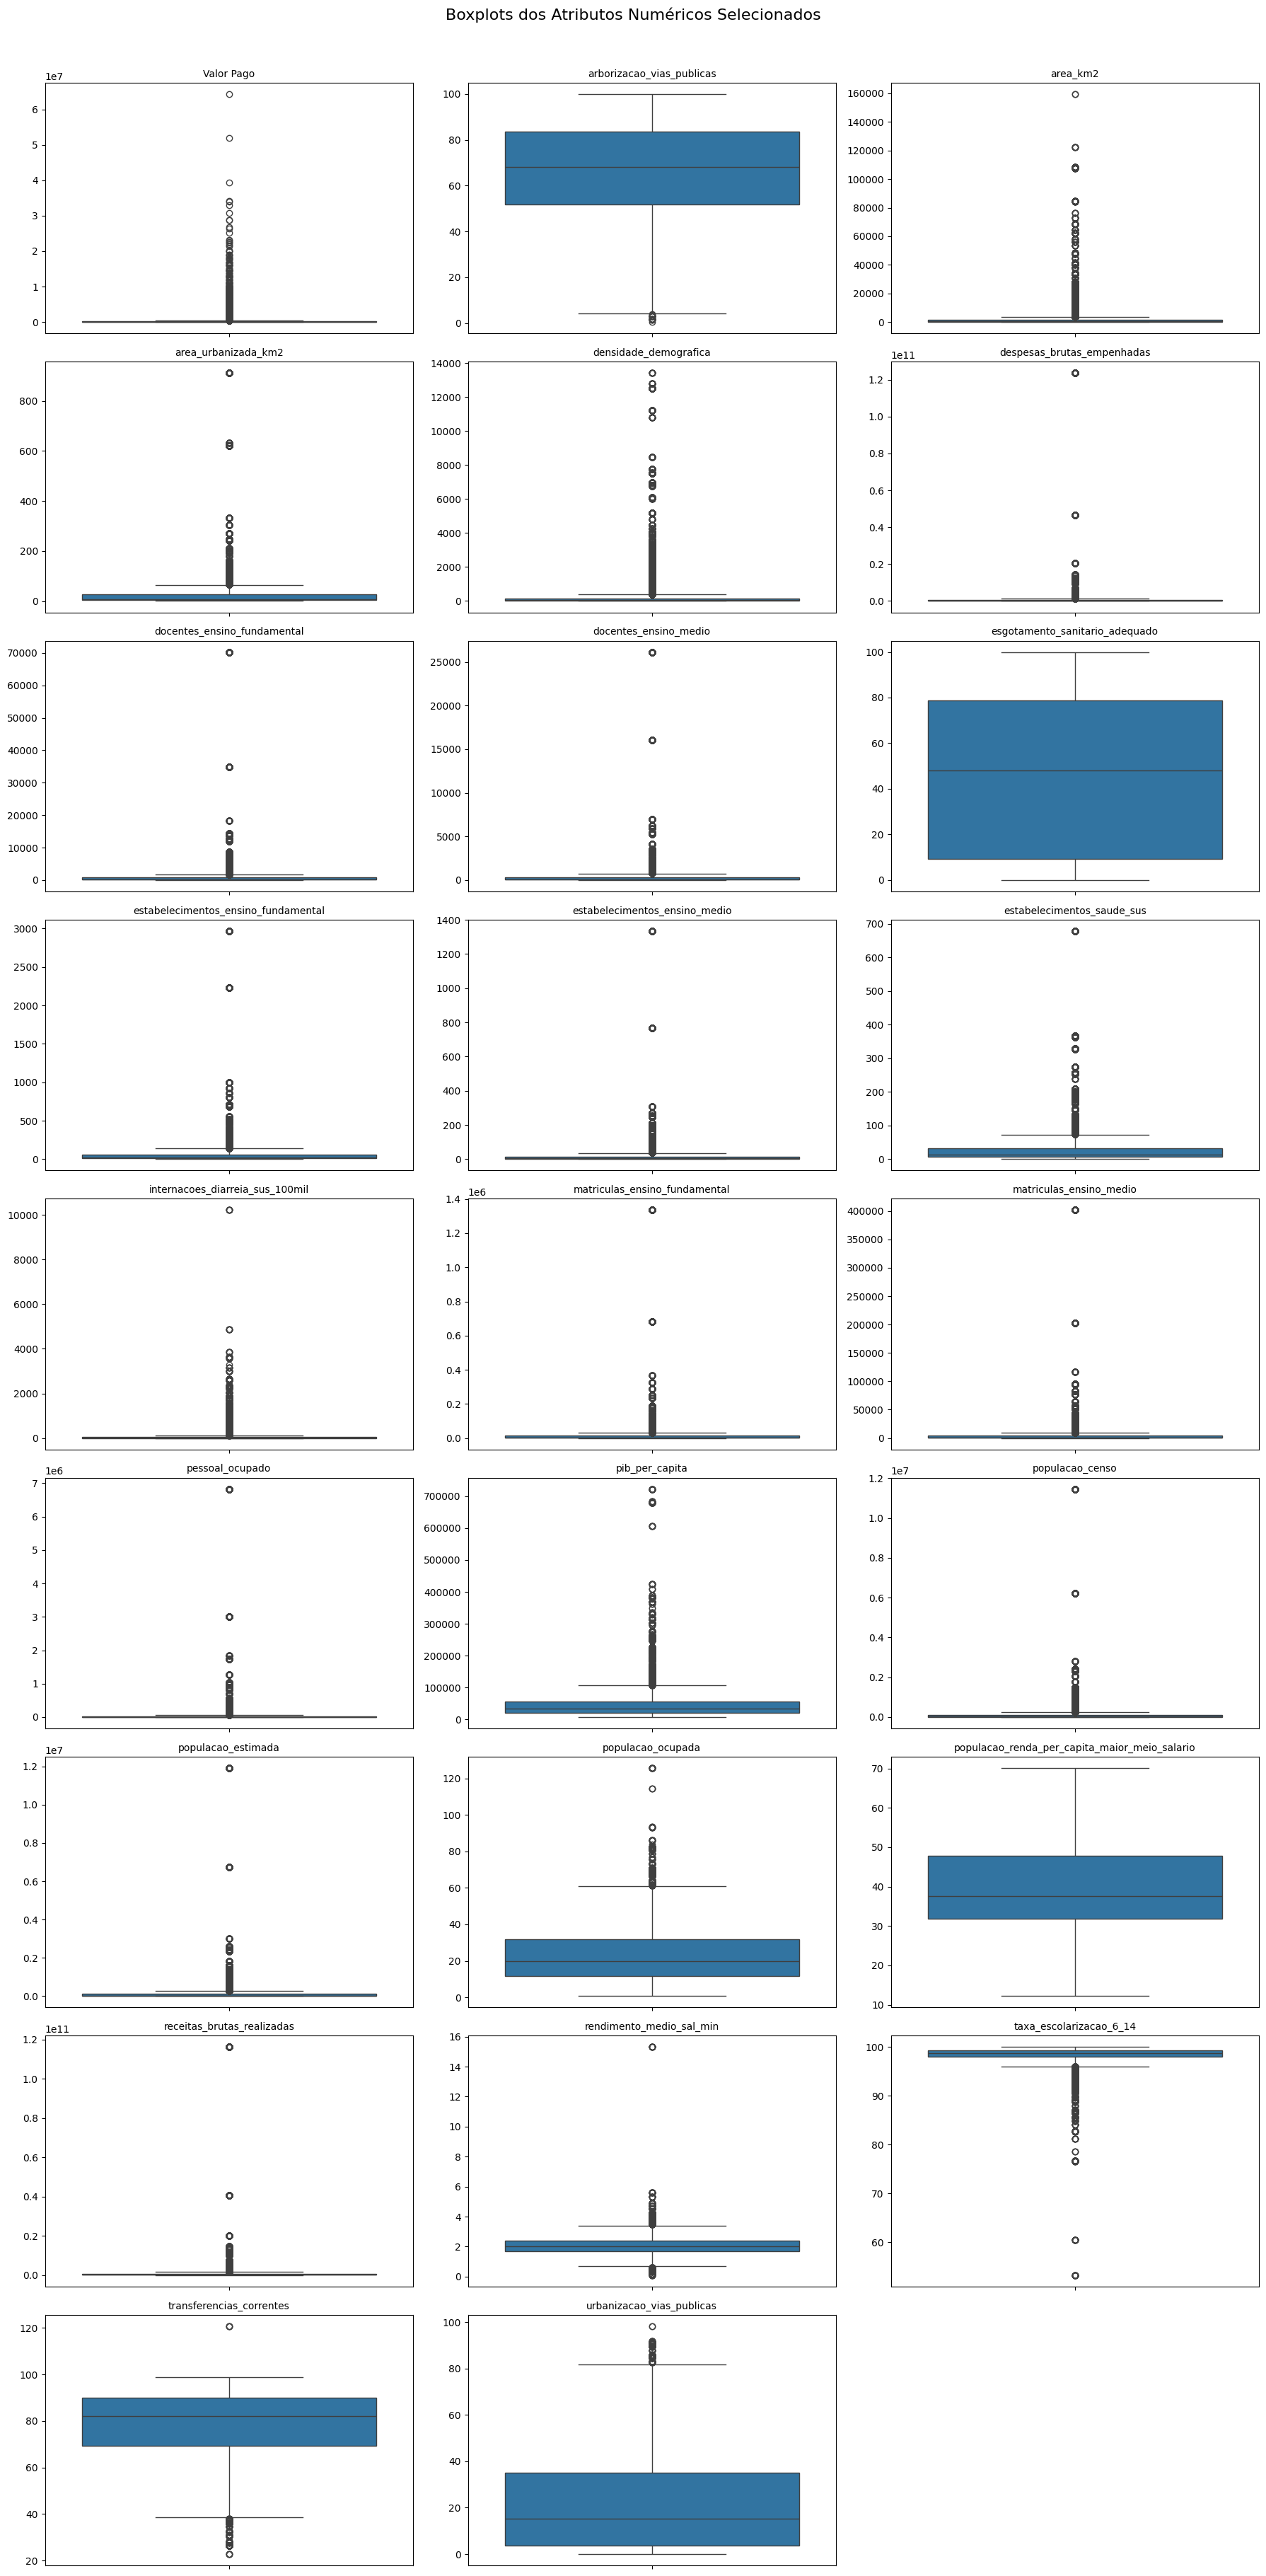

In [ ]:
# @title
import math

# Lista das variáveis numéricas desejadas pelo usuário
variaveis_selecionadas = [
    'Valor Pago', 'arborizacao_vias_publicas', 'area_km2', 'area_urbanizada_km2',
    'densidade_demografica', 'despesas_brutas_empenhadas', 'docentes_ensino_fundamental',
    'docentes_ensino_medio', 'esgotamento_sanitario_adequado', 'estabelecimentos_ensino_fundamental',
    'estabelecimentos_ensino_medio', 'estabelecimentos_saude_sus', 'internacoes_diarreia_sus_100mil',
    'matriculas_ensino_fundamental', 'matriculas_ensino_medio', 'mortalidade_infantil',
    'pessoal_ocupado', 'pib_per_capita', 'populacao_censo', 'populacao_estimada',
    'populacao_ocupada', 'populacao_renda_per_capita_maior_meio_salario', 'receitas_brutas_realizadas',
    'rendimento_medio_sal_min', 'taxa_escolarizacao_6_14', 'transferencias_correntes',
    'urbanizacao_vias_publicas'
]

# Filtrar apenas as variáveis que estão presentes no DataFrame
variaveis_disponiveis = [col for col in variaveis_selecionadas if col in df.columns]

# Definir o número de colunas por linha para o grid de subplots
n_cols = 3
n_rows = math.ceil(len(variaveis_disponiveis) / n_cols)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(18, 4 * n_rows))
plt.suptitle("Boxplots dos Atributos Numéricos Selecionados", y=1.01, fontsize=16)

# Nivelar o array de eixos para facilitar a iteração
axes_flat = axes.flatten()

for i, feature in enumerate(variaveis_disponiveis):
    sns.boxplot(y=df[feature], ax=axes_flat[i])
    axes_flat[i].set_title(feature, fontsize=10)
    axes_flat[i].set_ylabel("")

# Ocultar eixos não utilizados caso o número de variáveis não preencha o grid completamente
for j in range(i + 1, len(axes_flat)):
    fig.delaxes(axes_flat[j])

plt.tight_layout()
plt.show()

In [ ]:
# @title Exportação do dataset final

# Remover identificadores e colunas redundantes
colunas_remover = [
    'Código Município IBGE',
    'codigo_uf',
    'codigo_regiao'
]

df_final = df.drop(
    columns=colunas_remover,
    errors='ignore'
).copy()

# Conferir o resultado
print(f"Quantidade de registros: {len(df_final)}")
print(f"Quantidade de colunas: {len(df_final.columns)}")
print(f"Valores ausentes: {df_final.isna().sum().sum()}")


Quantidade de registros: 36229
Quantidade de colunas: 37
Valores ausentes: 311


In [ ]:

# Exportar o CSV
arquivo_final = 'EmendasParlamentares_DatasetLimpo.csv'

df_final.to_csv(
    arquivo_final,
    sep=';',
    index=False,
    encoding='utf-8-sig'
)

print(f"\nArquivo gerado: {arquivo_final}")

# Baixar o arquivo no Google Colab
from google.colab import files
files.download(arquivo_final)



Arquivo gerado: EmendasParlamentares_DatasetLimpo.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>